# 第10章 动态学习与模型辅助控制

实际执行的教学Notebook。所有数据为作者构造的W-H1充分混合水罐轨迹。先读取已训练模型，复算误差，再在同一参考环境中检查候选与回退。温度单位°C，误差单位K，功率单位kW，时间单位s。交互教学界面：仓库 `demo/ch10/index.html`。

## 1 载入训练模型与完整轨迹划分

训练统计量和网络参数已经导出；验证集选择16个隐藏单元。测试轨迹保留独立的动作扩展与高温初值。

In [1]:
from pathlib import Path
import sys, json, io
import numpy as np
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapters/ch10/model.py").exists())
sys.path.insert(0, str(root / "chapters/ch10"))
from model import load_bundle, predict, reference_step, linear_step, plan, execute_action
from run import fit_mlp, window_errors
D = json.loads((root / "results/ch10/experiment.json").read_text(encoding="utf-8"))
bundle = load_bundle()
for split in ["calibration", "train", "validation", "test"]:
    es = [e for e in D["episodes"] if e["split"] == split]
    print(split, "轨迹数:", len(es), "区间数:", sum(len(e["power"]) for e in es))
print("已选择宽度:", {k: v.get("width") for k, v in bundle["models"].items()})
print("训练轴对齐范围:", bundle["domain"])

calibration 轨迹数: 2 区间数: 240
train 轨迹数: 8 区间数: 1440
validation 轨迹数: 3 区间数: 540
test 轨迹数: 4 区间数: 720
已选择宽度: {'physical': None, 'direct': 16, 'residual': 16}
训练轴对齐范围: {'temperature': [30.0, 66.90079874431035], 'ambient': [17.400000352637345, 24.599987375593702], 'power': [0.0, 1.5]}


## 2 将动作加入状态推进，并核对机理特例

本单元在β=0的线性参考条件下对比DOP853与解析离散推进；带非线性散热的常规参考环境继续使用默认β。

In [2]:
T, Ta = 50.0, 22.0
for u in [0.0, 0.6, 1.2]:
    independent = reference_step(T, u, Ta, beta=0.0)
    analytic = linear_step(T, u, Ta, 418.0, 0.010)
    print(f"动作 {u:.1f} kW: 解析 {analytic:.8f} °C，积分 {independent:.8f} °C")
    assert abs(independent - analytic) < 1e-8
print("非线性参考 / 已辨识机理 / 残差模型:")
print(reference_step(T, 1.2, Ta), predict(bundle["models"]["physical"], T, 1.2, Ta), predict(bundle["models"]["residual"], T, 1.2, Ta))

动作 0.0 kW: 解析 49.91973250 °C，积分 49.91973250 °C
动作 0.6 kW: 解析 50.09173429 °C，积分 50.09173429 °C
动作 1.2 kW: 解析 50.26373608 °C，积分 50.26373608 °C
非线性参考 / 已辨识机理 / 残差模型:
50.23653743207537 50.26373608286264 50.2365301467206


## 3 实际重训一个小网络，读取开发选择依据

该单元只使用训练轨迹拟合8单元残差网络，并在验证轨迹上计算15步终点RMSE。完整run.py比较8与16单元后冻结选型。

In [3]:
train = [e for e in D["episodes"] if e["split"] == "train"]
validation = [e for e in D["episodes"] if e["split"] == "validation"]
small = fit_mlp("residual", 8, train, bundle["physics"])
err = np.concatenate([window_errors(small, e, 15) for e in validation])
score = float(np.sqrt(np.mean(err ** 2)))
record = next(x for x in D["selection"] if x["model"] == "residual" and x["width"] == 8)
print("本次8单元训练:", small["n_iter"], "次迭代；验证15步RMSE:", score, "K")
print("冻结记录:", record["validation_h15_rmse"], "K")
print("训练告警:", small["warnings"])
print("16单元开发结果:", next(x for x in D["selection"] if x["model"] == "residual" and x["width"] == 16)["validation_h15_rmse"], "K")
assert abs(score - record["validation_h15_rmse"]) < 1e-7

本次8单元训练: 155 次迭代；验证15步RMSE: 0.003614706385734011 K
冻结记录: 0.003614706385734011 K
训练告警: []
16单元开发结果: 0.0023667425891564686 K


## 4 绘制相同动作序列下的递推预测

改变episode_id、start和horizon，观察高温测试中的方法排序。这里输出的是当前单窗口沿途RMSE和终点误差；全轨迹的h步终点RMSE在冻结评测表中另行登记。

physical 当前窗口沿途RMSE: 2.18238 K；终点误差: 3.685 K
direct 当前窗口沿途RMSE: 0.15636 K；终点误差: 0.27544 K
residual 当前窗口沿途RMSE: 0.31223 K；终点误差: 0.54197 K


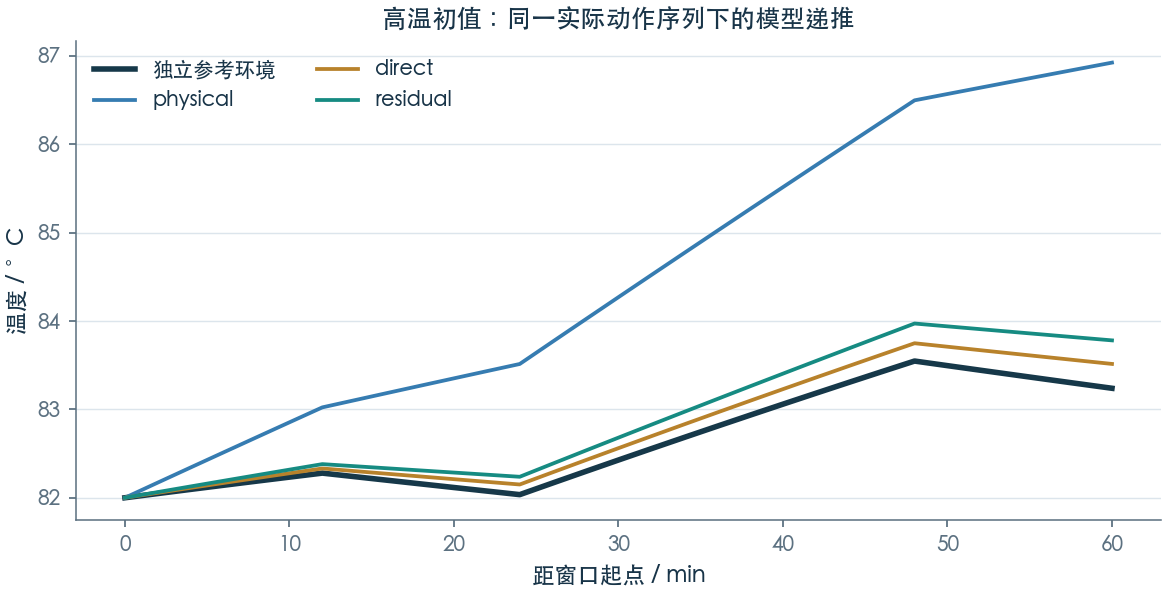

In [4]:
from visual_style import setup, style, plt
from IPython.display import Image, display
setup()
episode_id, start, horizon = "test_hot", 0, 30
ep = next(e for e in D["episodes"] if e["id"] == episode_id)
truth = np.array(ep["temperature"][start:start+horizon+1])
time_min = np.arange(horizon+1) * 2
fig, ax = plt.subplots(figsize=(7.3, 3.7), layout="constrained")
ax.plot(time_min, truth, color="#163849", linewidth=2.5, label="独立参考环境")
for name, color in [("physical", "#367cb1"), ("direct", "#b8822b"), ("residual", "#168b82")]:
    state = truth[0]; trajectory = [state]
    for j in range(horizon):
        state = predict(bundle["models"][name], state, ep["power"][start+j], ep["ambient"][start+j]); trajectory.append(state)
    error = np.array(trajectory[1:]) - truth[1:]
    print(name, "当前窗口沿途RMSE:", round(float(np.sqrt(np.mean(error**2))), 5), "K；终点误差:", round(float(error[-1]), 5), "K")
    ax.plot(time_min, trajectory, color=color, linewidth=1.7, label=name)
ax.set(xlabel="距窗口起点 / min", ylabel="温度 / °C", title="高温初值：同一实际动作序列下的模型递推")
style(ax); ax.legend(frameon=False, ncol=2)
buffer = io.BytesIO(); fig.savefig(buffer, format="png", dpi=160); plt.close(fig)
display(Image(data=buffer.getvalue()))

## 5 复算一个真实规划时刻的候选与代价

候选在整个12步内保持恒定功率，各方法共享已知环境和目标。实际闭环下一时刻重新规划；下表记录当前模型对恒定候选的评估。

In [5]:
run = next(c for c in D["control"] if c["scenario"] == "extended_power" and c["policy"] == "guarded_residual")
sc = next(s for s in D["control_scenarios"] if s["id"] == run["scenario"])
k = 30; row = run["rows"][k]
result = plan(bundle["models"]["residual"], row["T_before"], sc["ambient"][k:k+12], sc["target"][k+1:k+13], run["rows"][k-1]["action"], sc["action_grid"], bundle["domain"], bundle["physics"])
for c in result["candidates"]:
    print(f"{c['action']:.1f} kW | 代价 {c['cost']:.3f} | 域检查 {c['domain_ok']} | 物理检查 {c['physical_ok']} | 可用 {c['feasible']}")
print("规划请求:", result["action"], "kW；冻结记录:", row["requested_action"], "kW")
assert result["action"] == row["requested_action"]

0.0 kW | 代价 68.658 | 域检查 True | 物理检查 True | 可用 True
0.4 kW | 代价 56.118 | 域检查 True | 物理检查 True | 可用 True
0.8 kW | 代价 44.988 | 域检查 True | 物理检查 True | 可用 True
1.2 kW | 代价 35.271 | 域检查 True | 物理检查 True | 可用 True
1.6 kW | 代价 26.965 | 域检查 False | 物理检查 True | 可用 False
2.0 kW | 代价 20.067 | 域检查 False | 物理检查 True | 可用 False
2.4 kW | 代价 14.576 | 域检查 False | 物理检查 True | 可用 False
规划请求: 1.2 kW；冻结记录: 1.2 kW


## 6 分别检查回退请求、联锁与实际执行

高温82°C触发训练域检查及公共80°C联锁。联锁检查的是当前观测；[15,85]°C是候选预测的物理温度范围，两者分别承担执行与预测约束。

In [6]:
for T in [82.0, 79.0, float("nan")]:
    request = plan(bundle["models"]["residual"], T, np.full(12,22.), np.full(12,62.), 0., np.linspace(0,2.4,7), bundle["domain"], bundle["physics"])
    action, interlock = execute_action(T, request["action"], 2.4)
    print("观测:", T, "回退类型:", request["fallback_kind"], "请求:", request["action"], "实际动作:", action, "执行联锁:", interlock)
hot = next(c for c in D["control"] if c["scenario"] == "hot_start" and c["policy"] == "guarded_residual")
m = hot["metrics"]
print("完整高温闭环:", {key: m[key] for key in ["fallback_requested_count", "fallback_executed_count", "fallback_overridden_count", "interlock_count"]})
assert m["fallback_requested_count"] == m["fallback_executed_count"] + m["fallback_overridden_count"]
print("练习：同时记录预测误差、跟踪RMSE、用电及回退事件，解释扩展动作条件下保护与可达性的关系。")

观测: 82.0 回退类型: physical_feedback 请求: 0.0 实际动作: 0.0 执行联锁: True
观测: 79.0 回退类型: physical_feedback 请求: 0.0 实际动作: 0.0 执行联锁: False
观测: nan 回退类型: zero_power 请求: 0.0 实际动作: 0.0 执行联锁: True
完整高温闭环: {'fallback_requested_count': 63, 'fallback_executed_count': 56, 'fallback_overridden_count': 7, 'interlock_count': 7}
练习：同时记录预测误差、跟踪RMSE、用电及回退事件，解释扩展动作条件下保护与可达性的关系。
